<a href="https://colab.research.google.com/github/emircan-sen/patates-fiyati-tahmini/blob/main/patates_fiyat_tahmini_3_gunluk_pencereleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Türkiye'de Patates Fiyat Tahmini — 3 Günlük Pencereleme ile Doğrusal Regresyon

**Ders:** Makine Öğrenmesi  
**Amaç:** Türkiye'deki Konya Büyükşehir Belediyesi açık veri kaynağından alınan patates hal fiyatlarını kullanarak, önceki 3 fiyat gözleminden sonraki fiyat gözlemini tahmin etmek; `model.coef_`, `model.intercept_` ve `std_error` değerlerini hesaplayıp yorumlamak.

## Veri seti

- **Kaynak:** Konya Büyükşehir Belediyesi Açık Veri Portalı — Meyve-Sebze Hal Fiyatları
- **Veri:** Konya Meyve-Sebze Hali fiyatları, TL cinsinden
- **Sütunlar:** `tarih`, `urun_ad`, `birim`, `en_dusuk_fiyat`, `en_yuksek_fiyat` (ayrıca `tur`)
- **CSV sayfası:** https://acikveri.konya.bel.tr/tr/dataset/meyve-sebze-hal-fiyatlari
- **Kaynak dosyası:** https://acikveri-konya.digitalcosmonot.com/dataset/0a341ce8-4369-4d91-93d7-a302298275ad/resource/532c336b-b3b4-42f9-ae46-44d0597e3ff9/download/hal_fiyatlari.csv

**Veri güncelliği notu:** Portalda bu dosyanın son veri güncellemesi 26 Aralık 2023 olarak gösteriliyor. Bu nedenle çalışma Türkiye'deki **geçmiş Konya hal fiyatları** üzerinedir; 2026 güncel market fiyatlarını temsil etmez. Raporunuzda kaynak ve bu sınırlılığı belirtin.

**Fiyat hedefi:** Veri seti her ürün ve tarih için en düşük ve en yüksek hal fiyatını veriyor. Tek bir hedef değişken oluşturmak için bu ikisinin ortalamasını (`(en_dusuk_fiyat + en_yuksek_fiyat) / 2`) kullanıyoruz. Tam adı `PATATES` olan kg ürünü varsa öncelikle onu; yoksa adı PATATES içeren kg kayıtlarını kullanıyoruz.

**Pencereleme notu:** Hal fiyatları hafta sonları ve bazı tatil günlerinde yayımlanmayabileceği için pencereler üç **ardışık fiyat kaydından** oluşur. Yani bu, takvim üzerinde mutlaka üç arka arkaya gün demek değildir. Bu tercih, eksik günlere yapay fiyat yazmamızı önler.

## 1. Gerekli kütüphaneler

Google Colab'da bu notebook'u açın. Ardından **Çalışma zamanı → Tümünü çalıştır** seçeneğini kullanabilirsiniz.

In [ ]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)
print('Kütüphaneler hazır.')

Kütüphaneler hazır.


## 2. Türkiye veri setini yükleme

Dosya, Konya Büyükşehir Belediyesi Açık Veri Portalı kaynağından okunur. İlk satırları ve sütunları kontrol ederek beklenen verinin geldiğinden emin oluyoruz.

In [ ]:
CSV_URL = (
    'https://acikveri-konya.digitalcosmonot.com/dataset/'
    '0a341ce8-4369-4d91-93d7-a302298275ad/resource/'
    '532c336b-b3b4-42f9-ae46-44d0597e3ff9/download/hal_fiyatlari.csv'
)

df = pd.read_csv(CSV_URL, encoding='utf-8-sig')
df.columns = df.columns.str.strip().str.lower()

print('Ham satır sayısı:', len(df))
print('Sütunlar:', df.columns.tolist())
display(df.head())

Ham satır sayısı: 121840
Sütunlar: ['tarih', 'urun_ad', 'birim', 'tur', 'en_dusuk_fiyat', 'en_yuksek_fiyat']


,tarih,urun_ad,birim,tur,en_dusuk_fiyat,en_yuksek_fiyat
0,2004-03-02,ARMUT( Ankara ),Kg,1,1.60,1.70
1,2004-03-02,AYVA,Kg,1,0.55,0.30
2,2004-03-02,BAKLA,Kg,0,1.60,1.80
3,2004-03-02,BİBER (Çarli),Kg,0,1.10,1.30
4,2004-03-02,BİBER (Dolma),Kg,0,1.10,1.55


## 3. Patatesin kilogram fiyatını hazırlama

Önce ürün adı ve birim alanlarını temizliyoruz. `PATATES` isimli kg kaydı bulunursa onu kullanıyoruz. Tam isim yoksa `PATATES` kelimesini içeren kg ürünlerini bulup aynı tarihteki kayıtların ortalamasını kullanıyoruz. Hedef fiyat, en düşük ve en yüksek fiyatın orta noktasıdır.

In [ ]:
gerekli_sutunlar = {'tarih', 'urun_ad', 'birim', 'en_dusuk_fiyat', 'en_yuksek_fiyat'}
if not gerekli_sutunlar.issubset(df.columns):
    raise ValueError(
        'Beklenen sütunlar bulunamadı. Mevcut sütunlar: '
        f'{df.columns.tolist()}'
    )

df['tarih'] = pd.to_datetime(df['tarih'], errors='coerce')
df['urun_ad_temiz'] = df['urun_ad'].astype(str).str.strip().str.upper()
df['birim_temiz'] = df['birim'].astype(str).str.strip().str.upper()
df['en_dusuk_fiyat'] = pd.to_numeric(df['en_dusuk_fiyat'], errors='coerce')
df['en_yuksek_fiyat'] = pd.to_numeric(df['en_yuksek_fiyat'], errors='coerce')

kg = df[df['birim_temiz'].isin(['KG', 'KİLOGRAM', 'KILOGRAM'])].copy()
patates_adaylari = kg[kg['urun_ad_temiz'].str.contains('PATATES', na=False)].copy()

if patates_adaylari.empty:
    raise ValueError(
        'Veri setinde kg biriminde PATATES kaydı bulunamadı. '
        'Ürün adlarını kontrol etmek için df["urun_ad"].unique() çıktısına bakın.'
    )

# Tam ürün adı varsa karışık türleri bir araya getirmemek için onu seç.
tam_patates = patates_adaylari[patates_adaylari['urun_ad_temiz'].eq('PATATES')]
if not tam_patates.empty:
    patates = tam_patates.copy()
    secilen_urunler = sorted(patates['urun_ad'].dropna().astype(str).unique())
else:
    # Exact PATATES yoksa patates içeren isimleri kullan.
    patates = patates_adaylari.copy()
    secilen_urunler = sorted(patates['urun_ad'].dropna().astype(str).unique())

# Eksik tarih/fiyatları çıkar; mantıksız en düşük > en yüksek kayıtları kullanma.
patates = patates.dropna(subset=['tarih', 'en_dusuk_fiyat', 'en_yuksek_fiyat'])
patates = patates[
    (patates['en_dusuk_fiyat'] >= 0) &
    (patates['en_yuksek_fiyat'] >= 0) &
    (patates['en_dusuk_fiyat'] <= patates['en_yuksek_fiyat'])
].copy()

if patates.empty:
    raise ValueError('Temizleme sonrasında geçerli patates fiyatı kalmadı.')

patates['fiyat_orta_nokta'] = (
    patates['en_dusuk_fiyat'] + patates['en_yuksek_fiyat']
) / 2

# Aynı tarihte birden fazla kayıt varsa günlük ortalama fiyatı hesapla.
gunluk = patates.groupby('tarih')['fiyat_orta_nokta'].mean().sort_index()
gunluk.name = 'patates_fiyati_tl_kg'

gunluk_df = gunluk.to_frame().reset_index()
print('Seçilen ürün adı/adları:', secilen_urunler)
print('Fiyat gözlemi sayısı:', len(gunluk))
print('İlk gözlem tarihi:', gunluk.index.min().date())
print('Son gözlem tarihi:', gunluk.index.max().date())
print('Fiyatların birimi: TL/kg (en düşük ve en yüksek hal fiyatının orta noktası)')
display(gunluk_df.head())
display(gunluk_df.tail())

Seçilen ürün adı/adları: ['PATATES']
Fiyat gözlemi sayısı: 1389
İlk gözlem tarihi: 2004-03-02
Son gözlem tarihi: 2023-12-25
Fiyatların birimi: TL/kg (en düşük ve en yüksek hal fiyatının orta noktası)


,tarih,patates_fiyati_tl_kg
0,2004-03-02,4.50
1,2004-03-18,3.75
2,2004-04-05,4.00
3,2004-04-12,3.25
4,2004-05-07,3.25


,tarih,patates_fiyati_tl_kg
1384,2023-12-11,13.0
1385,2023-12-14,13.0
1386,2023-12-18,13.0
1387,2023-12-21,10.5
1388,2023-12-25,14.5


## 4. Üç kayıtlık pencereleme (windowing)

Her örnekte önceki üç fiyat kaydı girdi (`X`), bir sonraki kayıt hedef (`y`) olur. Örneğin kayıt 1, 2 ve 3 kullanılarak kayıt 4 tahmin edilir; ardından pencere bir kayıt ilerletilir.

In [ ]:
feature_names = ['fiyat_3_kayit_once', 'fiyat_2_kayit_once', 'fiyat_1_kayit_once']
X_satirlari = []
y_degerleri = []
hedef_tarihleri = []

for i in range(3, len(gunluk)):
    pencere = gunluk.iloc[i-3:i]
    hedef = gunluk.iloc[i]
    X_satirlari.append(pencere.to_numpy(dtype=float))
    y_degerleri.append(float(hedef))
    hedef_tarihleri.append(gunluk.index[i])

X = pd.DataFrame(X_satirlari, columns=feature_names)
y = pd.Series(y_degerleri, name='hedef_fiyat')
hedef_tarihleri = pd.Series(hedef_tarihleri, name='hedef_tarihi')

if len(X) < 20:
    raise ValueError(f'Yeterli 3 kayıtlık pencere oluşmadı: {len(X)} örnek.')

print('Oluşan pencere sayısı:', len(X))
print('Örnek girdiler ve hedef:')
_ornek = X.head(5).copy()
_ornek['hedef_fiyat'] = y.head(5).to_numpy()
_ornek['hedef_tarihi'] = hedef_tarihleri.head(5).dt.date.to_numpy()
display(_ornek)

Oluşan pencere sayısı: 1386
Örnek girdiler ve hedef:


,fiyat_3_kayit_once,fiyat_2_kayit_once,fiyat_1_kayit_once,hedef_fiyat,hedef_tarihi
0,4.50,3.75,4.00,3.25,2004-04-12
1,3.75,4.00,3.25,3.25,2004-05-07
2,4.00,3.25,3.25,3.00,2004-05-10
3,3.25,3.25,3.00,3.00,2004-05-20
4,3.25,3.00,3.00,3.00,2004-05-24


In [ ]:
# Fiyat kayıtları arasındaki tarih aralıklarını kontrol et
tarih_farklari = gunluk.index.to_series().diff().dt.days

print("Kayıtlar arasındaki gün farkları:")
print(tarih_farklari.value_counts().sort_index())

print("\nArdışık takvim günü olan kayıtların oranı:")
print(f"{(tarih_farklari == 1).mean() * 100:.2f}%")

Kayıtlar arasındaki gün farkları:
tarih
1.0        5
2.0       10
3.0      615
4.0      603
5.0       11
6.0        7
7.0       74
8.0        6
10.0       8
11.0      15
12.0       1
13.0       1
14.0      12
16.0       1
17.0       1
18.0       1
19.0       1
21.0       2
24.0       2
25.0       1
35.0       2
39.0       1
45.0       1
66.0       1
121.0      1
194.0      1
245.0      1
269.0      1
280.0      1
340.0      1
Name: count, dtype: int64

Ardışık takvim günü olan kayıtların oranı:
0.36%


## 5. Eğitim/test ayırma ve regresyon modelini eğitme

Zaman sırasını koruyoruz: ilk %80 eğitim, son %20 test verisi olur. Böylece ileriki tarihlerdeki kayıtları rastgele biçimde eğitim kümesine karıştırmıyoruz.

In [ ]:
sinir = int(len(X) * 0.80)
X_train, X_test = X.iloc[:sinir], X.iloc[sinir:]
y_train, y_test = y.iloc[:sinir], y.iloc[sinir:]
tarih_test = hedef_tarihleri.iloc[sinir:]

model = LinearRegression()
model.fit(X_train, y_train)
tahmin = model.predict(X_test)

print('Eğitim örneği:', len(X_train))
print('Test örneği:', len(X_test))
print('Model eğitildi.')

Eğitim örneği: 1108
Test örneği: 278
Model eğitildi.


## 6. `model.coef_`, `model.intercept_` ve standart hata (`std_error`)

- **`model.coef_`:** Önceki üç fiyat kaydının her biri için öğrenilen katsayıdır. Diğer girdiler sabit tutulduğunda ilgili fiyat bir TL/kg arttığında tahminin ne yönde değiştiği hakkında bilgi verir.
- **`model.intercept_`:** Doğrusal denklemin sabit terimidir. Önceki üç fiyat sıfır olduğundaki matematiksel kesişimi ifade eder; gerçek piyasa fiyatı olarak yorumlanmamalıdır.
- **`std_error`:** Aşağıdaki tabloda her katsayının OLS standart hatasıdır. Küçük standart hata, katsayı tahmininin belirsizliğinin görece daha düşük olabileceğini gösterir; tek başına modelin iyi olduğunu kanıtlamaz.
- `sklearn` içindeki `LinearRegression` katsayı standart hatasını doğrudan sağlamaz. Bu yüzden aynı eğitim verisi üzerinde `statsmodels` OLS kurarak `bse` değerlerini çıkarıyoruz.

In [ ]:
print('model.coef_ =', model.coef_)
print('model.intercept_ =', model.intercept_)

X_train_ols = sm.add_constant(X_train, has_constant='add')
ols_sonuc = sm.OLS(y_train, X_train_ols).fit()

katsayi_tablosu = pd.DataFrame({
    'Değişken': ['intercept'] + feature_names,
    'Katsayı': [model.intercept_] + model.coef_.tolist(),
    'std_error': ols_sonuc.bse.to_numpy(),
    'p_değeri': ols_sonuc.pvalues.to_numpy()
})
display(katsayi_tablosu.round(6))

artiklar = y_train.to_numpy() - model.predict(X_train)
serbestlik_derecesi = len(y_train) - (X_train.shape[1] + 1)
residual_std_error = np.sqrt(np.sum(artiklar ** 2) / serbestlik_derecesi)
print(f'Artıkların standart hatası (Residual Standard Error): {residual_std_error:.4f} TL/kg')

model.coef_ = [0.13850303 0.21336235 0.592743  ]
model.intercept_ = 0.1098095362820306


,Değişken,Katsayı,std_error,p_değeri
0,intercept,0.109810,0.030025,0.000267
1,fiyat_3_kayit_once,0.138503,0.029756,0.000004
2,fiyat_2_kayit_once,0.213362,0.034121,0.000000
3,fiyat_1_kayit_once,0.592743,0.029805,0.000000


Artıkların standart hatası (Residual Standard Error): 0.5569 TL/kg


## 7. Test başarısını değerlendirme

MAE tahminlerin ortalama mutlak hatasını, RMSE büyük hataları daha çok cezalandıran hata ölçüsünü, R² ise test kümesindeki değişimin ne kadarının model tarafından açıklandığını gösterir. R² negatif de çıkabilir; bu durumda test döneminde model, test hedeflerinin ortalamasını kullanmaktan daha kötü performans göstermiş olabilir.

In [ ]:
mae = mean_absolute_error(y_test, tahmin)
rmse = np.sqrt(mean_squared_error(y_test, tahmin))
r2 = r2_score(y_test, tahmin)

print(f'MAE  : {mae:.4f} TL/kg')
print(f'RMSE : {rmse:.4f} TL/kg')
print(f'R²   : {r2:.4f}')

sonuc_tablosu = pd.DataFrame({
    'Tarih': pd.to_datetime(tarih_test).to_numpy(),
    'Gerçek fiyat (TL/kg)': y_test.to_numpy(),
    'Tahmin edilen fiyat (TL/kg)': tahmin
})
sonuc_tablosu['Mutlak hata (TL/kg)'] = (
    sonuc_tablosu['Gerçek fiyat (TL/kg)'] -
    sonuc_tablosu['Tahmin edilen fiyat (TL/kg)']
).abs()
display(sonuc_tablosu.tail(10).round(3))

MAE  : 0.4030 TL/kg
RMSE : 0.6564 TL/kg
R²   : 0.9757


,Tarih,Gerçek fiyat (TL/kg),Tahmin edilen fiyat (TL/kg),Mutlak hata (TL/kg)
268,2023-11-23,13.0,12.390,0.610
269,2023-11-27,13.0,12.390,0.610
270,2023-11-30,13.0,12.390,0.610
271,2023-12-04,13.0,12.390,0.610
272,2023-12-07,13.0,12.390,0.610
273,2023-12-11,13.0,12.390,0.610
274,2023-12-14,13.0,12.390,0.610
275,2023-12-18,13.0,12.390,0.610
276,2023-12-21,10.5,12.390,1.890
277,2023-12-25,14.5,10.908,3.592


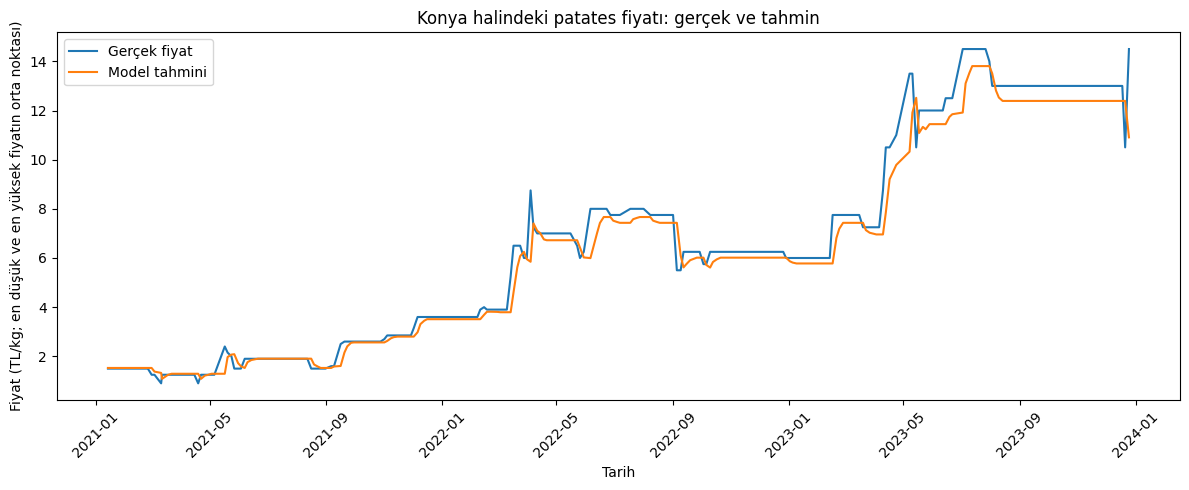

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(tarih_test, y_test, label='Gerçek fiyat')
plt.plot(tarih_test, tahmin, label='Model tahmini')
plt.title('Konya halindeki patates fiyatı: gerçek ve tahmin')
plt.xlabel('Tarih')
plt.ylabel('Fiyat (TL/kg; en düşük ve en yüksek fiyatın orta noktası)')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 8. Son üç fiyat kaydıyla sıradaki gözlem için tahmin

Veri kaynağı geçmiş fiyatları içerdiğinden, aşağıdaki çıktı **son kayıt tarihinden sonraki fiyat gözlemi için model tahminidir**. Hâlde her takvim günü kayıt yayımlanmadığı için bunun kesin olarak “yarının fiyatı” olduğunu söylemiyoruz.

In [ ]:
son_pencere = gunluk.tail(3)
if len(son_pencere) < 3:
    print('Tahmin için en az üç fiyat kaydı bulunamadı.')
else:
    yeni_girdi = pd.DataFrame([son_pencere.to_numpy(dtype=float)], columns=feature_names)
    gelecek_tahmin = float(model.predict(yeni_girdi)[0])
    print('Kullanılan son üç fiyat kaydı:')
    display(son_pencere.to_frame())
    print(f'Son veri tarihi: {son_pencere.index[-1].date()}')
    print(f'Sıradaki fiyat gözlemi için tahmin: {gelecek_tahmin:.2f} TL/kg')

Kullanılan son üç fiyat kaydı:


,patates_fiyati_tl_kg
tarih,
2023-12-18,13.0
2023-12-21,10.5
2023-12-25,14.5


Son veri tarihi: 2023-12-25
Sıradaki fiyat gözlemi için tahmin: 12.75 TL/kg


# Patates Fiyatı Tahmini: Doğrusal Regresyon ve Pencereleme

## 1. Çalışmanın Amacı

Bu çalışmanın amacı, geçmiş patates fiyatlarından yararlanarak bir sonraki fiyat kaydını tahmin edebilen bir makine öğrenmesi modeli oluşturmaktır. Çalışmada Python programlama dili, Google Colab ortamı ve doğrusal regresyon algoritması kullanılmıştır.

## 2. Veri Seti

Çalışmada Konya Büyükşehir Belediyesi Açık Veri Portalı'ndaki meyve-sebze hal fiyatları veri setinden yararlanılmıştır. Veri setindeki patates fiyatları kullanılarak tahmin modeli oluşturulmuştur. Fiyatlar TL/kg cinsinden değerlendirilmiştir.

Veri setinde her takvim günü için fiyat kaydı bulunmadığından, tahmin işleminde önceki üç fiyat kaydı esas alınmıştır.

## 3. Pencereleme Yöntemi

Pencereleme yöntemi, geçmişteki belirli sayıda gözlemi kullanarak sonraki gözlemi tahmin etmek için uygulanmıştır. Bu çalışmada pencere boyutu 3 olarak belirlenmiştir.

Modelin girdileri önceki üç fiyat kaydı, hedef değişkeni ise bu kayıtlardan sonraki fiyat değeridir. Bu yöntemle toplam 1.386 örnek oluşturulmuştur.

Örneğin, önceki fiyat kayıtları 4,50 TL, 3,75 TL ve 4,00 TL ise model bu üç değeri kullanarak bir sonraki fiyat kaydını tahmin etmeye çalışır. Bu işlemde üç ardışık takvim günü yerine önceki üç fiyat kaydı kullanılmıştır.

## 4. Doğrusal Regresyon Modeli

Doğrusal regresyon, değişkenler arasındaki doğrusal ilişkiyi kullanarak sayısal tahminler yapan bir yöntemdir.

Modelin genel denklemi şöyledir:

ŷ = b₀ + b₁x₁ + b₂x₂ + b₃x₃

Burada ŷ tahmin edilen fiyatı, b₀ sabit terimi, b₁, b₂ ve b₃ regresyon katsayılarını; x₁, x₂ ve x₃ ise önceki üç fiyat kaydını temsil etmektedir.

Veri, zaman sırası korunarak eğitim ve test kümelerine ayrılmıştır. Böylece model geçmiş verilerle eğitilmiş ve daha sonraki kayıtlar üzerinde değerlendirilmiştir.

## 5. Model Katsayıları

Model çalıştırıldığında aşağıdaki değerler elde edilmiştir:

- **`model.coef_`:** 0,138503; 0,213362; 0,592743
- **`model.intercept_`:** 0,109810

Buna göre model denklemi şöyledir:

ŷ = 0,109810 + 0,138503x₁ + 0,213362x₂ + 0,592743x₃

Katsayıların tamamı pozitiftir. Diğer değişkenler sabit tutulduğunda, geçmiş fiyatlardaki artış modelin tahmin ettiği fiyatı artırma yönünde etki gösterir.

En yüksek katsayı 0,592743 ile en yakın geçmiş fiyat kaydına aittir. Bu durum, modelin önceki fiyat kaydıyla daha güçlü bir doğrusal ilişki kurduğunu göstermektedir.

## 6. Standart Hata Analizi

Regresyon analizinde elde edilen standart hata değerleri aşağıdaki gibidir:

| Değişken | Katsayı | Standart Hata |
|---|---:|---:|
| Sabit terim | 0,109810 | 0,030025 |
| Üç kayıt önceki fiyat | 0,138503 | 0,029756 |
| İki kayıt önceki fiyat | 0,213362 | 0,034121 |
| Bir kayıt önceki fiyat | 0,592743 | 0,029805 |

Standart hata, katsayı tahminlerindeki belirsizliği değerlendirmeye yardımcı olur. Ayrıca regresyon tablosunda tüm değişkenlerin p-değerleri 0,05'in altındadır. Bu sonuç, modelin istatistiksel varsayımları altında katsayıların sıfırdan farklı olduğuna ilişkin kanıt bulunduğunu göstermektedir.

Modelin artık standart hatası (Residual Standard Error) 0,5569 TL/kg olarak hesaplanmıştır.

## 7. Model Başarı Ölçütleri

Modelin test verileri üzerindeki performansı üç ölçütle değerlendirilmiştir:

| Ölçüt | Sonuç |
|---|---:|
| MAE | 0,4030 TL/kg |
| RMSE | 0,6564 TL/kg |
| R² | 0,9757 |

**MAE (Ortalama Mutlak Hata):** Tahmin edilen fiyatlarla gerçek fiyatlar arasındaki mutlak farkların ortalamasıdır. Modelin MAE değeri 0,4030 TL/kg'dır.

**RMSE (Kök Ortalama Kare Hata):** Tahmin hatalarının karelerini dikkate alır ve büyük hatalara daha fazla ağırlık verir. Modelin RMSE değeri 0,6564 TL/kg'dır.

**R² (Belirlilik Katsayısı):** Modelin test verilerindeki fiyat değişkenliğinin ne kadarını açıkladığını gösterir. 0,9757 değeri, test kümesindeki değişkenliğin yaklaşık %97,57'sinin model tarafından açıklandığını göstermektedir.

Bu sonuçlar, modelin test verilerinde yüksek bir uyum gösterdiğine işaret etmektedir. Ancak bu başarı, modelin gelecekte her zaman aynı doğrulukla tahmin yapacağını garanti etmez.

## 8. Genel Değerlendirme ve Sonuç

Bu çalışmada geçmiş patates fiyatlarını kullanarak bir sonraki fiyat kaydını tahmin etmek amacıyla doğrusal regresyon modeli geliştirilmiştir. Üç fiyat kaydını girdi olarak kullanan pencereleme yöntemiyle 1.386 örnek oluşturulmuştur.

Model sonucunda MAE 0,4030 TL/kg, RMSE 0,6564 TL/kg ve R² 0,9757 olarak bulunmuştur. Regresyon katsayıları, sabit terim ve standart hata değerleri incelenerek modelin tahmin davranışı değerlendirilmiştir.

Sonuç olarak model, kullanılan test verilerinde yüksek bir uyum göstermiştir. Bununla birlikte, fiyatların zaman içinde değişebileceği ve bazı dönemlerde ani artış veya düşüşlerin görülebileceği dikkate alınmalıdır.

## 9. Kullanılan Araçlar

- Python
- Google Colab
- Pandas
- NumPy
- Scikit-learn
- Statsmodels
- Matplotlib

Bu araçlar veri hazırlama, pencereleme, regresyon modelini oluşturma, sonuçları değerlendirme ve görselleştirme işlemlerinde kullanılmıştır.